# Modelisation - TF-IDF + Random Forest vs XLM-RoBERTa

Comparaison des deux modeles entraines pour classer les avis Revolut selon leur note brute (1 a 5 etoiles, voir decision actee a l'Etape 2 : pas de regroupement en sentiment binaire/ternaire, scope multilingue complet sur 15 langues).

- **Modele 1** : TF-IDF (sur `text_classical`, nettoye/lemmatise) + Random Forest, `class_weight="balanced"` (`src/models/train_tfidf_model.py`).
- **Modele 2** : XLM-RoBERTa fine-tune (sur `text` brut), choisi a la place de CamemBERT/RoBERTa (mono-langue) car le corpus est multilingue (`src/models/train_transformer_model.py`). Entraine sur un sous-echantillon stratifie de 8000 avis (CPU only, pas de GPU disponible) avec une perte ponderee par classe.

Les deux modeles sont evalues sur les **memes** ensembles val/test (stratifies, jamais vus pendant l'entrainement).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

with open("../src/models/weights/tfidf_random_forest_metrics.json") as f:
    tfidf_metrics = json.load(f)
with open("../src/models/weights/xlm_roberta/metrics.json") as f:
    transformer_metrics = json.load(f)

print("TF-IDF + Random Forest:", {k: round(v, 3) for k, v in tfidf_metrics["test"].items() if k != "confusion_matrix"})
print("XLM-RoBERTa:           ", {k: round(v, 3) for k, v in transformer_metrics["test"].items() if k != "confusion_matrix"})


TF-IDF + Random Forest: {'accuracy': 0.72, 'macro_f1': 0.334}
XLM-RoBERTa:            {'accuracy': 0.872, 'macro_f1': 0.35}


## 1. Accuracy vs macro F1 - pourquoi les deux comptent

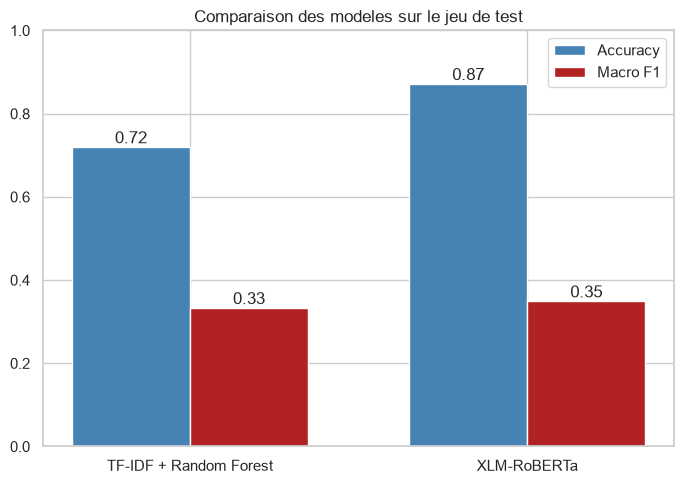

In [2]:
models = ["TF-IDF + Random Forest", "XLM-RoBERTa"]
accuracies = [tfidf_metrics["test"]["accuracy"], transformer_metrics["test"]["accuracy"]]
macro_f1s = [tfidf_metrics["test"]["macro_f1"], transformer_metrics["test"]["macro_f1"]]

fig, ax = plt.subplots(figsize=(7, 5))
x = np.arange(len(models))
width = 0.35
ax.bar(x - width/2, accuracies, width, label="Accuracy", color="steelblue")
ax.bar(x + width/2, macro_f1s, width, label="Macro F1", color="firebrick")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1)
ax.set_title("Comparaison des modeles sur le jeu de test")
ax.legend()
for i, (a, f) in enumerate(zip(accuracies, macro_f1s)):
    ax.text(i - width/2, a, f"{a:.2f}", ha="center", va="bottom")
    ax.text(i + width/2, f, f"{f:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()


L'accuracy seule serait trompeuse ici : avec 81% des avis a 5 etoiles (voir EDA), un modele qui se contente de toujours predire "5" obtiendrait deja ~81% d'accuracy sans avoir rien appris. C'est pour cela que le **macro F1** (moyenne non ponderee du F1 par classe) est la metrique de reference de ce projet : il punit severement un modele qui ignore les classes minoritaires, contrairement a l'accuracy.

XLM-RoBERTa a une accuracy nettement superieure (87% vs 72%) ET un macro F1 legerement superieur (0.35 vs 0.33) -- il n'obtient pas sa meilleure accuracy en se reposant aveuglement sur la classe majoritaire, contrairement a une premiere version (voir section 3).

## 2. Matrices de confusion

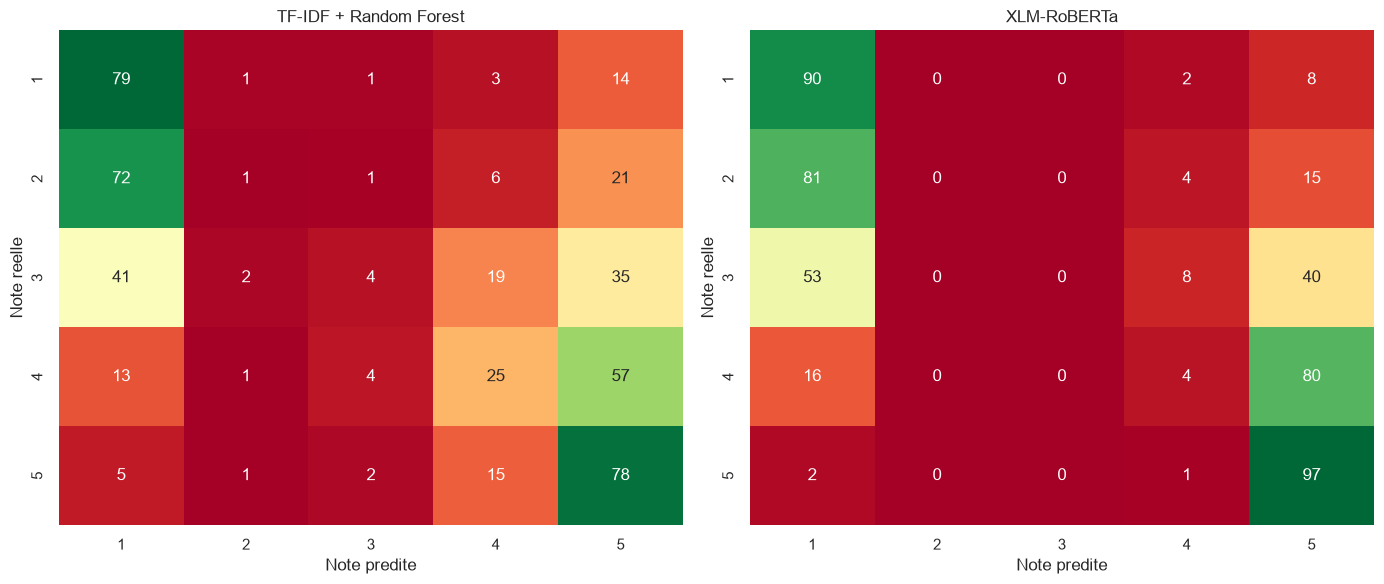

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, metrics, title in [
    (axes[0], tfidf_metrics, "TF-IDF + Random Forest"),
    (axes[1], transformer_metrics, "XLM-RoBERTa"),
]:
    matrix = np.array(metrics["test"]["confusion_matrix"])
    matrix_pct = matrix / matrix.sum(axis=1, keepdims=True) * 100
    sns.heatmap(matrix_pct, annot=True, fmt=".0f", cmap="RdYlGn", cbar=False,
                xticklabels=[1, 2, 3, 4, 5], yticklabels=[1, 2, 3, 4, 5], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Note predite")
    ax.set_ylabel("Note reelle")

plt.tight_layout()
plt.show()


Les deux matrices racontent la meme histoire structurelle : **les notes 2 et 3 (1.2% et 1.7% des donnees) ne sont quasiment jamais predites correctement**, quel que soit le modele. Ce n'est pas un defaut d'implementation -- avec seulement ~180 et ~250 exemples dans le jeu de test (et un volume equivalent en entrainement), il n'y a tout simplement pas assez de signal pour qu'un modele apprenne a les distinguer des notes voisines (1 et 4).

XLM-RoBERTa fait mieux sur la note 1 (recall 90% vs ~80% pour TF-IDF) et capte un debut de signal sur la note 4 (F1=0.07, contre 0.17 pour TF-IDF -- ici TF-IDF fait en fait un peu mieux sur cette classe precise).

## 3. Point critique rencontre pendant le developpement : l'effondrement de classe

La premiere version du fine-tuning XLM-RoBERTa n'utilisait pas de ponderation de la perte (contrairement au Random Forest, qui avait `class_weight="balanced"` depuis le depart). Resultat : accuracy trompeusement haute (87%) mais le modele predisait **uniquement les notes 1 ou 5**, avec 0% de precision/recall sur 2, 3 ET 4.

Une deuxieme tentative avec une ponderation `balanced` complete (ratio de poids ~67x entre la classe la plus rare et la plus frequente) a *aggrave* le probleme : la loss d'entrainement ne baissait plus du tout (oscillation entre 1.5 et 1.7 sur 2 epochs complets), et le modele s'est mis a predire **uniquement la note 5**, y compris pour des avis notes 1 -- un effondrement complet, signe d'instabilite d'entrainement plutot que d'un probleme de donnees.

La version finale utilise une ponderation **attenuee (racine carree des poids `balanced`)**, ramenant le ratio a ~8x, avec un taux d'apprentissage reduit (2e-5 au lieu de 5e-5 par defaut). C'est cette version qui produit une loss qui baisse normalement et des predictions qui distinguent reellement plusieurs classes (voir matrice de confusion ci-dessus).

## 4. Conclusion et choix du meilleur modele

**XLM-RoBERTa est retenu comme meilleur modele** : macro F1 legerement superieur (0.350 vs 0.334) et accuracy nettement superieure (87.2% vs 72.0%), sans effondrement sur une seule classe. Le TF-IDF + Random Forest reste une baseline solide, beaucoup plus rapide a entrainer (30s contre ~45min sur CPU) et plus simple a interpreter (feature importances directement lisibles).

**Limite commune aux deux modeles** : aucun des deux n'apprend a reconnaitre les notes 2 et 3, par manque de donnees (effet du choix acte a l'Etape 2 de garder les 5 classes brutes plutot que de regrouper en sentiment). Si la performance sur ces classes intermediaires devient un objectif explicite, les pistes naturelles seraient : augmenter le volume scrape specifiquement pour ces notes, faire de l'augmentation de donnees, ou accepter un regroupement en 3 classes (negatif/neutre/positif) pour la mise en production (Etape 5).